# Le rôle des ouvertures aux échecs, inspiré du Jeu de la dame

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hadrienfonrojet/ANALYSE-MARCHE-/blob/main/QueensGambit.ipynb)

Dans *Le Jeu de la dame*, Beth Harmon imagine un échiquier au plafond et joue mentalement plusieurs suites de coups. Cette scène illustre ce qui fait des échecs un jeu de stratégie : dès l’ouverture, les joueurs entrent dans des schémas qu’ils apprennent à reconnaître et à rejouer. Ces schémas nous donnent un point de départ pour étudier la répétition : après une victoire, les joueurs reviennent-ils plus souvent à la même famille d’ouverture ?

## Problématique

Après une victoire, rejoue-t-on plus souvent la même famille d’ouverture ? Lorsqu’on la rejoue, gagne-t-on plus souvent la partie suivante, à niveau, couleur et cadence comparables ?

## Sommaire

* **I. Collecter les données**
  * I.1 Sélection des comptes par marche aléatoire
  * I.2 Téléchargement des parties classées via l’API Lichess
  * I.3 Sauvegarde et chargement de la collecte brute

* **II. Nettoyer et construire la base**
  * II.1 Référentiel et identification des familles d’ouverture
  * II.2 Nettoyage et contrôle du codage des résultats

* **III. Décrire les résultats**
  * III.1 Niveau des joueurs et résultats selon la couleur
  * III.2 Taux de victoire, de défaite et de nulle par famille d’ouverture
  * III.3 Ouvertures les plus jouées et séries de résultats

* **IV. Répéter une ouverture après une victoire**
  * IV.1 Fréquence de répétition selon le résultat précédent
  * IV.2 Victoire suivante après répétition ou changement d’ouverture
  * IV.3 Test du χ² et régressions

* **V. Couleur, sessions de jeu et revanches**
  * V.1 Répétition à couleur identique et régression avec effet fixe joueur
  * V.2 Rang dans la session et enchaînement des victoires
  * V.3 Parties successives contre le même adversaire et bilan des tests

L’analyse repose sur la collecte Lichess publiée dans `donnees/parties_1an.parquet`.

# Partie 1 — Collecter les données

La collecte ne s’exécute pas dans ce notebook : elle interroge l’API de Lichess pendant 15 à 45 minutes. Elle est lancée une fois, depuis un terminal, par `Master_file.py`. Le notebook relit ensuite le fichier qu’elle a produit. Les sections 1.1 à 1.4 décrivent comment ce fichier a été fabriqué ; les sections 1.5 à 1.7 le chargent et regardent ce qu’il contient.

## 1.1 Pourquoi une API plutôt que du web scraping

Afin de télécharger les données nécessaires à notre analyse, nous avons choisi d'utiliser l'API Lichess, qui est publique, plutôt que de passer par du web scraping. En effet, en se connectant à notre compte Lichess, nous avons obtenu un jeton de connexion et l'avons donné dans les paramètres de config pour que nous puissions échanger par fichier json.
Nous avons choisi un format NDJSON afin d'éviter les bugs de collecte de données, et car cela permet une communication partie par partie (une partie par ligne json), plutôt que de renvoyer un fichier global avec une réponse contenant toutes les parties. 

```python
payload = "".join(
    json.dumps(g, ensure_ascii=False) + "\n"
    for g in games
).encode("utf-8")
```

## 1.2 Choisir les comptes : trois graines et une marche aléatoire

On part de trois comptes « graines » : `macaquezizi`, `T34USSR` et `lucascrotti`. Ces comptes sont des utilisateurs possédant un ELO différent, ce qui nous permet de couvrir des niveaux de jeu variés ; l’échantillon reste toutefois propre à ces comptes et à leurs adversaires, et ne représente pas l’ensemble des joueurs du site. Pour chaque graine, on utilise la fonction discover_users_random_walk(), qui lit les 10 dernières parties du compte, relève ses adversaires, en tire quelques-uns au hasard, puis on recommence depuis l’un d’eux pour compléter notre dataframe:

```python
candidates = [name for name in get_recent_opponents(current, token) if name not in known]
batch = rng.sample(candidates, take)      # tirer au hasard des adversaires encore inconnus
users.extend(batch)
current = rng.choice(batch)               # repartir de l’un d’eux
```

**Pourquoi.** Lichess ne fournit pas de liste de joueurs. Se déplacer de joueur en adversaire donne des comptes actifs, de niveaux variés. La graine aléatoire est fixée à 73 (`random.Random(73)`) : la même collecte relancée choisit les mêmes comptes. 

## 1.3 Télécharger les parties de chaque compte

Pour chaque compte et chaque cadence (bullet, blitz, rapid, classical), `extract_games_user()` (fichier `import_parties.py`) appelle l’adresse `https://lichess.org/api/games/user/{pseudo}` avec ces paramètres :

```python
params = {
    "max": nb_parties,          # plafond de parties par compte et par cadence
    "rated": "true",            # seulement les parties classées (avec Elo)
    "perfType": format_partie,  # une cadence à la fois
    "opening": "true",          # le nom d’ouverture donné par Lichess
    "moves": "true",            # la suite des coups, pour identifier nous-mêmes l’ouverture
    "finished": "true",         # seulement les parties terminées
}
```

**Pourquoi.** Les parties classées ont un Elo, indispensable pour comparer des joueurs de niveaux différents. Les coups permettent d’identifier l’ouverture avec notre propre règle (partie 2). 

## 1.4 Conserver et partager la collecte

Chaque réponse brute est enregistrée telle quelle (`api_<pseudo>_<cadence>.ndjson`) avec une fiche de contrôle (paramètres), sans jamais écraser un fichier existant. `Master_file.py` réunit tout dans `dfs_games_brut.parquet`, puis, avec l’option `--upload`, copie la collecte sur le stockage du SSP Cloud. Garder la réponse brute permet de refaire toute l’analyse sans réinterroger Lichess, et de prouver sur quelles données elle porte si bien qu'un utilisateur externe aura le même jeu de données que nous sur son test. Le fichier `donnees/parties_1an.parquet` publié dans le dépôt est cette base brute.

La commande qui a produit cette collecte, lancée dans un terminal du SSP Cloud avec `USERS_PER_SEED=10` et `GAMES_PER_FORMAT=300` dans le fichier `.env` (une dizaine de comptes par graine, au plus 300 parties par compte et par cadence, sur un an) :

```bash
python Master_file.py --collect --discover --since 2025-11-25 --until 2026-11-25 --debut 2026-05-01 --fin 2026-11-01 --upload
```

## 1.5 Préparer l’environnement

### 1.5.1 Importer les bibliothèques de calcul

On prépare l’environnement et on importe toutes les bibliothèques nécessaires à notre analyse. 


| Bibliothèque | Rôle dans le projet |
|---|---|
| `pathlib`, `os`, `sys`, `subprocess` | Se placer dans le bon dossier ; sur Colab, cloner le dépôt et installer les dépendances |
| `hashlib`, `io`, `json` | Empreintes des fichiers, lecture d’un fichier reçu du cloud, fichiers de paramètres |
| `numpy`, `pandas` | Calcul numérique et manipulation des tables de parties |
| `matplotlib`, `IPython.display` | Graphiques et affichage des tableaux |
| `scipy`, `statsmodels` | Tests du χ² et régressions |

Sur le SSP Cloud ou en local, le bloc ne fait qu’importer. Sur Colab, où le dépôt n’est pas présent, il le clone depuis GitHub et installe `requirements.txt`.

In [1]:
from pathlib import Path
import os
import sys
import subprocess
import warnings
import hashlib
import io
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Image
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
# Se placer à la racine du projet (le dossier qui contient config.py).
if not Path("config.py").is_file() and Path("../config.py").is_file():
    os.chdir("..")
if not Path("config.py").is_file():  # Cas Colab : le dépôt n’est pas encore là.
    target = Path("/content/jeu_de_la_dame")
    if not target.exists():
        subprocess.run(["git", "clone", "https://github.com/Hadrienfonrojet/ANALYSE-MARCHE-.git", str(target)], check=True)
    os.chdir(target)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, str(Path.cwd()))  # Rendre les modules du projet importables.


L’environnement est complet : Python, pandas 3 et NumPy 2 sont chargés, ainsi que les bibliothèques de tests (`scipy`) et de régression (`statsmodels`). Les versions sont aussi enregistrées dans la fiche de reproductibilité à la fin du notebook.

### 1.5.2 Charger la configuration, socle du projet

Le fichier `config.py` est la base de tout le projet : tous les autres fichiers le lisent. Il contient :

- les **chemins** (`Data/`, `Resultats/`, `References/`) ;
- les **paramètres de collecte** : comptes graines, cadences, nombre de parties par cadence, graine aléatoire 73 ;
- la **version figée** du référentiel des ouvertures et la profondeur d’identification (5 à 10 coups) ;
- le **niveau d’analyse** des ouvertures (`NIVEAU_OUVERTURE = "famille"`) ;
- la lecture du fichier privé `.env`, qui garde le jeton Lichess et les clés du stockage hors du code et hors de GitHub.

Modifier un réglage dans `config.py` change le comportement de toute la chaîne, sans toucher aux autres fichiers.

In [3]:
import config as cfg

# Modules du projet : chacun s’appuie sur les réglages de config.py.
from import_ouvertures import creer_openings
from Master_file import identifier_parties
from nettoyage import preparer_parties
from analyse import (
    statistiques_ouvertures, statistiques_temporelles, series_resultats,
    regressions_lineaires, preparer_regressions, exporter_tableaux,
    tests_repetition, tracer_resultats, ecrire_manifeste,
)
from Analyse_repetition_ouverture import (
    preparer_cadres, taux_apres_victoire, tester_table,
)

La configuration confirme les trois réglages qui conditionnent tous les résultats : le référentiel d’ouvertures est figé à la version `712a58be`, les ouvertures sont étudiées au niveau de la famille d'ouverture, et l’identification rejoue entre 5 et 10 coups (c’est-à-dire qu’une ouverture est reconnue si les 5 premiers coups correspondent au schéma théorique de cette dernière). La graine aléatoire 73 rend la sélection des comptes reproductible, et identique à tous les utilisateurs du notebook.

### 1.5.3 Fixer les paramètres de l’analyse

**Objectif.** Toutes les décisions qui changent les résultats sont réunies dans une seule cellule et annoncées avant de regarder les données : la source, les dates de la fenêtre conservée dans les exports et le seuil d’affichage.

**Deux façons d’obtenir les parties**, selon `SOURCE` :

- **`"fichier"` — les parties sont déjà dans le dépôt.** La collecte a été faite une fois, puis le fichier `donnees/parties_1an.parquet` a été publié sur GitHub avec le code. Les parties y sont stockées « en dur » : n’importe qui peut relancer le notebook, sans réseau et sans identifiant, et obtenir exactement les mêmes chiffres. C’est le mode par défaut, celui qui garantit la reproductibilité.
- **`"s3"` — les parties sont dans le cloud.** Chaque collecte est aussi sauvegardée sur le stockage du SSP Cloud (`s3://hadrien2703/diffusion/projet_ouvertures/<collecte>/`). Ce mode va les chercher à distance. Il sert pour une collecte plus récente ou plus grosse que celle du dépôt ; il demande les clés d’accès du SSP Cloud et le nom de la collecte dans `S3_RUN_ID`.

In [4]:
SOURCE = "fichier"                            # "fichier" : parties publiées dans le dépôt ; "s3" : parties du stockage SSP Cloud.
LOCAL_FILE = "donnees/parties_1an.parquet"    # Utilisé si SOURCE = "fichier".
S3_RUN_ID = ""                                # Nom du dossier de collecte, utilisé si SOURCE = "s3".
DEBUT = "2026-05-01"                          # Exercice 2 : début inclus (UTC).
FIN = "2026-11-01"                            # Exercice 2 : fin exclue (UTC).
OUVERTURE = "Sicilian Defense"                # Famille étudiée en détail.
MIN_PARTIES = 20                              # Seuil d’affichage des familles dans les tableaux.

## 1.6 Charger les parties

 `cfg.create_run()` ouvre d’abord un dossier neuf `Collectes/<date>_<identifiant>/` : les résultats de cette exécution y seront rangés sans jamais écraser une exécution précédente. Ensuite :

- **si les parties sont dans le dépôt** (`"fichier"`), `pd.read_parquet` lit directement `donnees/parties_1an.parquet` : rien n’est téléchargé, la lecture est instantanée et identique pour tous ;
- **si elles sont dans le cloud** (`"s3"`), le client du SSP Cloud télécharge `dfs_games_brut.parquet` de la collecte demandée, puis pandas le lit en mémoire.

Dans les deux cas, on obtient la même table `brut` : une ligne par partie et par compte suivi. La suite du notebook ne dépend donc pas de la provenance des données.

In [5]:
cfg.create_run()  # Dossier neuf pour les résultats de cette exécution.

if SOURCE == "fichier":
    # Cas 1 : les parties sont déjà publiées dans le dépôt.
    path = Path(LOCAL_FILE)
    brut = pd.read_csv(path) if path.suffix.lower() == ".csv" else pd.read_parquet(path)
elif SOURCE == "s3":
    # Cas 2 : aller chercher la collecte sur le stockage SSP Cloud.
    if not S3_RUN_ID or Path(S3_RUN_ID).name != S3_RUN_ID or S3_RUN_ID in {".", ".."}:
        raise ValueError("Préciser un identifiant simple de collecte S3")
    from Stockage_SSPCloud import client
    key = f"{cfg.S3_PREFIX}/{S3_RUN_ID}/Data/dfs_games_brut.parquet"
    response = client().get_object(Bucket=cfg.S3_BUCKET, Key=key)
    try:
        brut = pd.read_parquet(io.BytesIO(response["Body"].read()))
    finally:
        response["Body"].close()
else:
    raise ValueError("SOURCE doit être fichier ou s3")

La base brute contient 13 727 lignes et 17 colonnes. `user_id` désigne le compte suivi et `game_id` la partie.

## 1.7 Ce que la collecte a ramené

Quatre comptages permettent de voir quels comptes, cadences et types de parties composent la base brute.

### 1.7.1 Combien de parties par compte ?

On classe les comptes selon le nombre de parties enregistrées.

In [6]:
par_compte = brut["user_id"].value_counts()
display(par_compte.head(5).to_frame("parties"))

,parties
user_id,
lucascrotti,1098
ojaijoao,1046
peonzen,832
deder87,797
gulf_titans,773


Les cinq comptes les plus actifs totalisent environ un tiers des parties. Ils pèsent donc davantage dans les taux calculés par observation.

### 1.7.2 Combien de parties par cadence ?

On compte les parties par cadence.

In [7]:
print(brut["format_partie"].value_counts().to_string())

format_partie
rapid        4393
bullet       4186
blitz        4115
classical    1033


Rapid, bullet et blitz comptent chacun plus de 4 000 parties. Le classique en compte 1 033.

### 1.7.3 Quelle période chaque compte couvre-t-il ?

On convertit les dates en UTC, puis on affiche les trois historiques les plus courts.

In [8]:
dates_brutes = pd.to_datetime(brut["timestamp_ms"], unit="ms", utc=True)
periode = dates_brutes.groupby(brut["user_id"]).agg(premiere="min", derniere="max")
periode["jours_couverts"] = (periode["derniere"] - periode["premiere"]).dt.days
print(periode.nsmallest(3, "jours_couverts")["jours_couverts"].to_string())

user_id
igetmykingoutfirst      0
brilliant-enterprise    3
killerchess1            6


La période couverte varie selon les comptes. Certains atteignent rapidement le plafond de collecte et ont donc un historique plus court.

### 1.7.4 Comment les parties se sont-elles terminées ?

On repère les principaux statuts de fin et les parties jouées depuis une position personnalisée.

In [9]:
statuts = brut["status"].value_counts()
print(statuts.reindex(["resign", "mate", "outoftime", "noStart"], fill_value=0).to_string())
print("fromPosition :", brut["variant"].eq("fromPosition").sum())

status
resign       6458
mate         3176
outoftime    3141
noStart        72
fromPosition : 218


Le nettoyage écarte notamment les parties non commencées et celles qui partent d’une position personnalisée.

# Partie 2 — Nettoyer et construire la base

On passe de la base brute à la base d’analyse en trois étapes, chacune dans son propre bloc : **charger le référentiel des ouvertures**, **identifier l’ouverture de chaque partie**, puis **nettoyer**. `brut` contient la source, `identifiees` ajoute la classification, et `parties` est la table nettoyée sur laquelle portent toutes les analyses.

## 2.1 Charger le référentiel officiel des ouvertures

Dans `import_ouvertures.py`, `creer_openings()` appelle `read_reference(directory)` pour charger les cinq fichiers officiels de Lichess. Pour chaque fichier, la lecture se fait ainsi.

```python
frame = pd.read_csv(path, sep="\t", dtype=str)
```

Le référentiel associe ensuite les suites de coups aux positions atteintes.

In [10]:
reference = creer_openings()

Le référentiel contient 3 865 ouvertures. On regroupe les variantes en familles pour comparer des groupes assez fournis.

## 2.2 Identifier l’ouverture de chaque partie

`identifier_parties()` rejoue les 10 premiers coups de chaque partie et cherche, à chaque demi-coup, si la position atteinte figure dans le référentiel. Elle retient la variante la plus précise atteinte. Une partie de moins de 5 coups reste « inconnue », en raison de notre choix de config.

**Pourquoi comparer des positions plutôt que des coups.** Deux ordres de coups différents peuvent mener à la même position  : ils reçoivent le même nom. Et nous appliquons la même règle à toutes les parties, au lieu de dépendre du nom fourni par l’API.

In [11]:
identifiees = identifier_parties(brut, reference)
display(identifiees["opening_identification_status"].value_counts().to_frame("parties"))

,parties
opening_identification_status,
identifiee,13318
variante_non_standard,218
partie_trop_courte,151
coups_absents,40


**13 318 parties sur 13 727 (97 %)** ont une ouverture identifiée par nos propres coups. Les autres sont les 218 variantes non standard, 151 parties trop courtes pour atteindre une position du référentiel et 40 parties sans coups. L’identification est donc quasi complète.

## 2.3 Nettoyer et faire le bilan

`preparer_parties()` harmonise les dates en UTC et les résultats, retire les parties sans résultat, les variantes non standard et les doublons, puis crée les variables d’analyse et regroupe les ouvertures par **famille** (le nom avant « : », par exemple *Sicilian Defense*). Elle renvoie la table `parties` et un `bilan` qui compte chaque opération.

In [12]:
parties, bilan = preparer_parties(identifiees)
print(pd.Series(bilan).to_string())

lignes_brutes                     13727
lignes_invalides_rejetees           271
identifiants_manquants_rejetes        0
doublons_retires                      0
lignes_nettoyees                  13456
parties_uniques                   13443
joueurs                              30
ouvertures_manquantes               138
elo_adverse_manquant                  0
dates_ex_aequo                        0
ruptures_historique                  87
joueurs_chronologie_incertaine        0


Le nettoyage rejette **271 lignes invalides** (positions de départ modifiées, parties non commencées ou sans coups) et ne trouve ni doublon ni date ex aequo. Il reste **13 456 lignes**, soit 13 443 parties uniques : 13 parties opposent deux comptes suivis et apparaissent donc deux fois, une fois par joueur. 138 lignes n’ont pas d’ouverture, et **87 ruptures d’historique** signalent un trou dans la suite des parties d’un compte : on ne reliera jamais deux parties de part et d’autre d’une rupture.

## 2.4 Contrôler les variables de résultat

On vérifie que chaque ligne correspond à une victoire, une défaite ou une nulle.

In [13]:
assert parties[["win", "loss", "draw"]].sum(axis=1).eq(1).all()

# Partie 3 — Premières statistiques descriptives

On décrit la base nettoyée avant toute recherche de lien : sa taille, le niveau des joueurs, les résultats, l’effet de la couleur, puis les trois exercices demandés (les familles d’ouverture, une fenêtre de temps, les séries). Ces chiffres servent de référence pour les parties 4 et 5.

## 3.1 Taille et période de l’échantillon

On compte séparément les lignes, les parties distinctes et les comptes, puis on relève la période couverte.


La base de travail contient **13 456 lignes de 30 comptes**, du 25 novembre 2025 au 24 novembre 2026 : une année complète, soit onze fois plus de parties que la collecte de test.

## 3.2 Le niveau des joueurs

On résume le classement Elo du joueur et de son adversaire, l’écart entre les deux et le score.

In [15]:
display(parties[["rating", "opponent_rating", "elo_diff", "score"]].agg(["count", "mean", "std", "min", "max"]).round(3))

,rating,opponent_rating,elo_diff,score
count,13456.000,13456.000,13456.000,13456.000
mean,1950.044,1860.323,89.722,0.585
std,539.141,495.631,252.165,0.481
min,474.000,400.000,-1539.000,0.000
max,2880.000,3064.000,1777.000,1.000


Les comptes suivis ont 1 950 Elo en moyenne, contre 1 860 pour leurs adversaires. Cet écart de 90 points aide à expliquer pourquoi ils gagnent plus d’une partie sur deux.

L’histogramme montre la répartition des écarts de niveau entre adversaires.

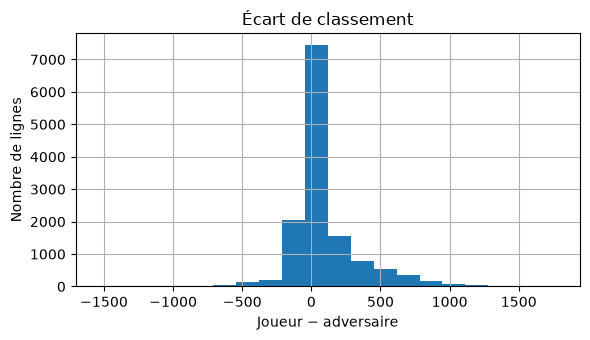

In [16]:
ax = parties.elo_diff.dropna().hist(bins=20, figsize=(6, 3.5))
ax.set(title="Écart de classement", xlabel="Joueur − adversaire", ylabel="Nombre de lignes")
plt.tight_layout()
plt.show()

L’écart Elo est très dispersé. On en tiendra compte dans les régressions sur le résultat.

## 3.3 Les résultats et le score

On calcule les taux de victoire, de défaite et de nulle, et le score moyen. Le score donne 1 point à une victoire, 0,5 à une nulle et 0 à une défaite.

In [17]:
print("Taux de victoire :", round(parties.win.mean(), 4))
print("Taux de défaite :", round(parties.loss.mean(), 4))
print("Taux de nulle :", round(parties.draw.mean(), 4))
print("Score moyen :", round(parties.score.mean(), 4))

Taux de victoire : 0.5611
Taux de défaite : 0.3917
Taux de nulle : 0.0472
Score moyen : 0.5847


Les comptes suivis gagnent **56,1 %** de leurs parties, en perdent 39,2 % et font nulle dans 4,7 % des cas. Le score moyen de 0,585 crédite chaque nulle d’un demi-point. Ce sont les valeurs de référence du notebook : un taux par ouverture ou par situation se compare à ces 56,1 %. Cela n'a pas de sens en lui même, néanmoins cela sera peut-être utile dans la comparaison avec le taux de victoire à la répétition d'une ouverture, ou dans une série temporelle.

## 3.4 La couleur

Aux échecs, les Blancs jouent le premier coup : on s’attend à un léger avantage. On le mesure dès maintenant, car c’est un point de référence (si nos données retrouvent cet effet connu, elles sont crédibles) et un contrôle indispensable pour la suite, où garder ou changer de couleur modifiera les chances de gagner.

On écrit d’abord deux petites fonctions, réutilisées dans toute la suite du notebook afin de ne pas répéter le même code :

- `taux(df, par)` donne, pour chaque groupe, le nombre de parties, le nombre de victoires, le taux de victoire et son **intervalle de confiance à 95 %**, $\hat p \pm 1{,}96\sqrt{\hat p(1-\hat p)/n}$ ;
- `chi2(df, x)` réalise le **test du χ² d’indépendance** entre `x` et la victoire, avec la p-value et le V de Cramér, qui mesure la force du lien entre 0 (aucun) et 1 (total).

Un taux sans effectif ni incertitude ne veut rien dire : 3 victoires sur 4 font 75 %, mais avec un intervalle de 33 % à 100 %. La liste `tests` garde tous les tests du notebook, afin de les corriger ensemble avant l’export.

In [18]:
def taux(df, par, cible="win_suiv"):
    t = df.groupby(par, observed=True)[cible].agg(parties="size", victoires="sum", taux="mean")
    marge = 1.96 * np.sqrt(t["taux"] * (1 - t["taux"]) / t["parties"])
    t["ic_bas"], t["ic_haut"] = (t["taux"] - marge).clip(0), (t["taux"] + marge).clip(upper=1)
    t["victoires"] = t["victoires"].astype(int)
    return t


def chi2(df, x, y="win_suiv"):
    tab = pd.crosstab(df[x], df[y])
    stat, p, ddl, attendu = chi2_contingency(tab, correction=False)
    v = np.sqrt(stat / (tab.values.sum() * (min(tab.shape) - 1)))
    return {"test": x, "n": int(tab.values.sum()), "chi2": round(float(stat), 3), "ddl": int(ddl),
            "p": round(float(p), 4), "V_Cramer": round(float(v), 3), "attendu_min": round(float(attendu.min()), 1)}

tests = []  # Tous les tests du notebook, corrigés ensemble par Holm avant l’export.
parties["couleur"] = parties["color"].map({"white": "Blancs", "black": "Noirs"})

On calcule le taux de victoire avec les Blancs et avec les Noirs, avec son intervalle de confiance, le nombre de nulles et le score moyen.

In [19]:
par_couleur = taux(parties, "couleur", cible="win")
par_couleur["nulles"] = parties.groupby("couleur")["draw"].sum()
par_couleur["score_moyen"] = parties.groupby("couleur")["score"].mean()
display(par_couleur.round(3))

,parties,victoires,taux,ic_bas,ic_haut,nulles,score_moyen
couleur,,,,,,,
Blancs,6755,3885,0.575,0.563,0.587,286,0.596
Noirs,6701,3665,0.547,0.535,0.559,349,0.573


Les Blancs gagnent **57,5 %** de leurs parties [56,3 ; 58,7], les Noirs **54,7 %** [53,5 ; 55,9] : les deux intervalles ne se chevauchent pas. Les Noirs font un peu plus de nulles (349 contre 286). L’avantage du premier coup est donc visible, de l’ordre de 3 points.

On teste ensuite le lien entre la couleur et le résultat (victoire, nulle, défaite), afin de savoir si l’écart observé peut venir du hasard.

In [20]:
t = chi2(parties, "couleur", y="result")
tests.append({**t, "test": "couleur × résultat (V/N/D)"})
print(t)

{'test': 'couleur', 'n': 13456, 'chi2': 14.457, 'ddl': 2, 'p': 0.0007, 'V_Cramer': 0.033, 'attendu_min': 316.2}


Le χ² confirme le lien entre couleur et résultat (χ² = 14,5, ddl = 2, **p = 0,0007**) ; il résistera à la correction pour tests multiples. Mais le V de Cramér de 0,033 indique un effet **faible** : la couleur compte, beaucoup moins que l’écart de classement. On la contrôlera donc dans les régressions.

## 3.5 Comparer les familles d’ouverture

 `statistiques_ouvertures()` (fichier `analyse.py`) crée une ligne par famille, avec ses effectifs, ses taux et son score moyen. Les nulles restent dans le dénominateur. Une dernière colonne donne le taux de victoire **équipondéré** : la moyenne des taux de chaque joueur, pour que chaque joueur pèse autant. On n’affiche que les familles jouées au moins `MIN_PARTIES` fois.

In [21]:
ouvertures = statistiques_ouvertures(parties)
colonnes = ["opening_name", "n_parties", "n_joueurs", "victoires", "defaites", "nulles", "taux_victoire", "taux_defaite", "taux_nulle", "score_moyen", "score_std", "taux_victoire_moyen_joueurs"]
frequentes = ouvertures[ouvertures.n_parties >= MIN_PARTIES].sort_values("n_parties", ascending=False)
print(f"{len(ouvertures)} familles au total ; {len(frequentes)} jouées au moins {MIN_PARTIES} fois "
      f"({frequentes.n_parties.sum()} parties sur {ouvertures.n_parties.sum()}).")
print(frequentes[colonnes].head(10).round(3).to_string(index=False))

119 familles au total ; 60 jouées au moins 20 fois (12928 parties sur 13318).
           opening_name  n_parties  n_joueurs  victoires  defaites  nulles  taux_victoire  taux_defaite  taux_nulle  score_moyen  score_std  taux_victoire_moyen_joueurs
       Sicilian Defense       1790         27       1015       676      99          0.567         0.378       0.055        0.595      0.477                        0.481
         French Defense       1033         27        618       357      58          0.598         0.346       0.056        0.626      0.469                        0.549
      Caro-Kann Defense        790         25        467       293      30          0.591         0.371       0.038        0.610      0.478                        0.609
      Queen's Pawn Game        763         27        421       310      32          0.552         0.406       0.042        0.573      0.484                        0.548
        English Opening        688         23        458       199      31   

Sur 119 familles, **60 atteignent le seuil de 20 parties** ; elles réunissent 12 928 des 13 318 parties dont l’ouverture est connue. La Sicilienne domine (1 790 parties), devant la Française (1 033), la Caro-Kann (790) et le Queen’s Pawn Game (763).

Les taux bruts vont de 31,7 % (Old Indian Defense, 41 parties) à 69,5 % (Queen’s Gambit Accepted, 59 parties). Mais la dernière colonne change souvent la lecture : la **Sicilienne** gagne 56,7 % de ses parties, mais seulement 48,1 % en moyenne par joueur ; la **Hungarian Opening** passe de 55,0 % à 37,8 %, la **Tarrasch** de 60,3 % à 33,0 % (6 joueurs). À l’inverse, la Bishop’s Opening passe de 56,7 % à 71,3 %. Quand les deux taux s’écartent autant, la famille est dominée par un ou deux comptes : le taux brut décrit ces joueurs, pas l’ouverture. Comparer des ouvertures sans tenir compte du niveau mènerait donc à de fausses conclusions.

In [ ]:
# Préparer les tables utilisées par les graphiques et les exports.
series, maxima = series_resultats(parties)
tracer_resultats(ouvertures, pd.DataFrame(), maxima, cfg.RESULTS_DIR)

Le graphique compare la part de victoires, de défaites et de nulles pour les familles les plus jouées.

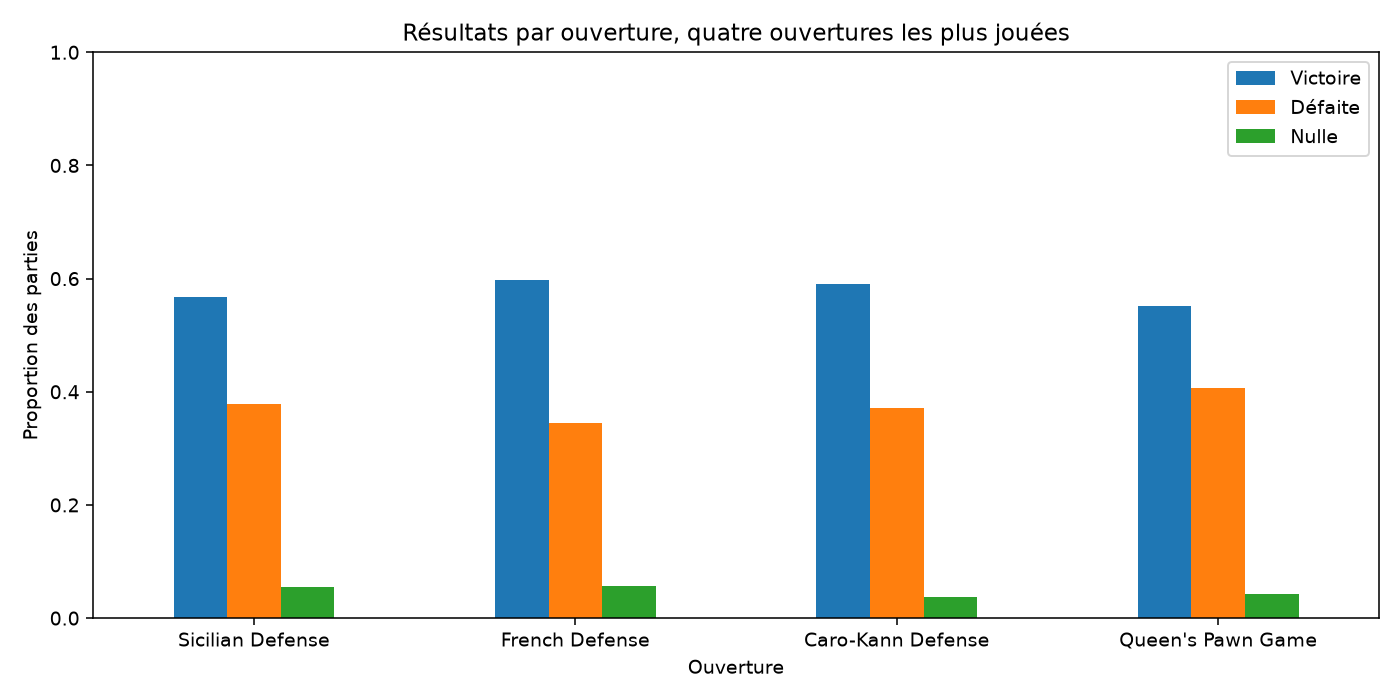

In [29]:
display(Image(filename=str(cfg.RESULTS_DIR / "taux_ouvertures.png")))

Parmi les familles les plus fréquentes, les taux bruts vont de 55,2 % pour le Queen’s Pawn Game à 59,8 % pour la Française. Ces taux dépendent aussi du niveau des joueurs qui ont joué chaque ouverture.

## 3.7 Les séries

Une série garde le même joueur, la même famille et le même résultat sur des parties consécutives. Victoire, nulle, victoire donne deux séries de victoires de longueur 1 : la nulle coupe la série. `series_resultats()` calcule sur l’historique complet, puis on sélectionne une famille.

### 3.7.1 Séries maximales sur toute la base

Pour chaque famille, on relève la plus longue série de victoires, de défaites et de nulles. Une longue série attire l’œil, mais il faut la comparer à ce que le hasard produirait.

In [27]:
display(maxima.sort_values("max_serie_victoire", ascending=False).head(15))

result,opening_name,max_serie_victoire,max_serie_defaite,max_serie_nulle
35,English Opening,6,3,1
46,Hungarian Opening,5,3,1
101,Sicilian Defense,5,3,1
39,French Defense,4,2,2
48,Italian Game,3,3,1
54,King's Indian Defense,3,2,1
19,Caro-Kann Defense,3,2,1
98,Scandinavian Defense,3,2,1
90,Queen's Pawn Game,3,3,1
111,Van't Kruijs Opening,3,3,1


La plus longue série avec la même famille est de six victoires avec l’English Opening. Les maxima sont de trois défaites et de deux nulles. Ces séries sont comptées dans la suite des parties observées pour chaque joueur.

# Partie 4 — Répéter l’ouverture après un succès

C’est la question centrale du projet. On prépare d’abord un nouveau jeu de données d’**enchaînements** (une partie et la suivante du même joueur), puis on compare la répétition et le changement de famille, d’abord sur tous les enchaînements, ensuite après une victoire seulement. On termine par des régressions, afin de vérifier si le lien résiste au niveau des joueurs.

## 4.1 Préparer les enchaînements de parties

Pour étudier l’effet de la répétition sur la partie suivante, il faut une ligne par partie avec les informations de la partie qui la suit chez le même joueur. On construit ce jeu de données en trois étapes.

### 4.1.1 Ajouter les informations de la partie suivante

On trie les parties de chaque joueur dans l’ordre chronologique, puis `shift(-1)` place sur chaque ligne les valeurs de la partie suivante du même joueur. Le suffixe `_suiv` désigne ces colonnes. Le `groupby("user_id")` évite de raccorder la dernière partie d’un joueur à la première du joueur suivant.

In [31]:
parties = parties.sort_values(["user_id", "date", "game_id"]).reset_index(drop=True)

g = parties.groupby("user_id", sort=False)
for col in ["game_id", "date", "opening_name", "color", "couleur", "win", "score",
            "opponent_id", "format_partie", "elo_diff", "_chronology_segment"]:
    parties[col + "_suiv"] = g[col].shift(-1)

On a ajouté à chaque partie les informations de la partie suivante du même compte. **13 426 lignes sur 13 456** ont une partie suivante : les 30 restantes sont la dernière partie de chaque compte.

### 4.1.2 Ne garder que les vraies successions

On garde une ligne si la partie suivante existe, si elle est plus tardive, et si aucune partie n’a été retirée entre les deux par le nettoyage (même `_chronology_segment`). Comparer deux parties séparées par une partie retirée reviendrait à inventer une succession.

In [32]:
valide = (parties["game_id_suiv"].notna()
          & parties["date_suiv"].gt(parties["date"])
          & parties["_chronology_segment"].eq(parties["_chronology_segment_suiv"])
          & ~parties["_date_ambiguous"])
trans = parties.loc[valide].copy()
print("Enchaînements valides :", len(trans), "sur", len(parties) - parties.user_id.nunique(), "possibles")

Enchaînements valides : 13339 sur 13426 possibles


**13 339 enchaînements** sont valides. Les 87 écartés franchissent une rupture d’historique (section 2.3) : relier ces deux parties reviendrait à supposer qu’elles se suivent alors qu’il manque des parties entre elles.

### 4.1.3 Créer les indicateurs

On crée les variables qui serviront dans les parties 4 et 5 :

- `repete` = 1 si la partie suivante est de la **même famille** (vide si une des deux familles est inconnue) ;
- `meme_couleur` = 1 si le joueur garde **la même couleur** ;
- `meme_adversaire` = 1 si la partie suivante est **contre le même adversaire** ;
- les contrôles : `blancs_suiv`, l’écart Elo divisé par 100, et le délai entre les deux parties.

La famille d’ouverture dépend **des deux joueurs** : avec les Blancs on joue 1.e4, c’est l’adversaire qui choisit la Sicilienne. « Répéter son ouverture » a donc surtout un sens quand on garde la même couleur, ce que la partie 5 étudie.

In [33]:
connues = trans["opening_name"].notna() & trans["opening_name_suiv"].notna()
trans["repete"] = (trans["opening_name"] == trans["opening_name_suiv"]).where(connues).astype("float")
trans["meme_couleur"] = (trans["color"] == trans["color_suiv"]).astype(int)
trans["meme_adversaire"] = (trans["opponent_id"] == trans["opponent_id_suiv"]).astype(int)
trans["blancs_suiv"] = (trans["color_suiv"] == "white").astype(int)
trans["elo_suiv_100"] = trans["elo_diff_suiv"].astype(float) / 100
trans["win_suiv"] = trans["win_suiv"].astype(float)
trans["ecart_min"] = (trans["date_suiv"] - trans["date"]).dt.total_seconds() / 60

Sur 13 072 enchaînements dont les deux familles sont connues, le joueur **répète sa famille dans 11,8 % des cas** seulement. Il garde la même couleur dans 32,8 % des cas, car Lichess alterne en général les couleurs. 1 062 enchaînements se jouent contre le même adversaire, et le délai médian entre deux parties est de 9,4 minutes : la plupart des enchaînements se font dans la même séance de jeu.

## 4.2 Répéter ou changer de famille

On compare le taux de victoire de la partie suivante selon que le joueur répète ou change de famille, d’abord sur tous les enchaînements, puis selon le résultat de la partie précédente. Répéter une ouverture, c’est jouer une position qu’on connaît : on peut s’attendre à un avantage de familiarité. Mais un joueur peut aussi répéter par habitude, quelle que soit sa forme.

### 4.2.1 Garder les enchaînements dont les deux familles sont connues

On ajoute deux libellés lisibles : le choix (répète ou change) et le résultat de la partie précédente.

In [34]:
rep = trans.dropna(subset=["repete"]).copy()
rep["choix"] = rep["repete"].map({1.0: "Répète la famille", 0.0: "Change de famille"})
rep["partie_precedente"] = rep["win"].map({1: "après une victoire", 0: "après une nulle ou défaite"})

### 4.2.2 Le taux de victoire selon le choix

On calcule le taux de victoire de la partie suivante quand on répète et quand on change de famille. L’écart entre ces deux taux donne une première mesure de l’association, avant de tenir compte du niveau des joueurs.

In [35]:
display(taux(rep, "choix").round(3))

,parties,victoires,taux,ic_bas,ic_haut
choix,,,,,
Change de famille,11534,6487,0.562,0.553,0.571
Répète la famille,1538,841,0.547,0.522,0.572


Le taux de victoire de la partie suivante est presque le même quand on répète sa famille (**54,7 %**, 1 538 enchaînements) et quand on en change (**56,2 %**, 11 534) ; les intervalles de confiance se chevauchent largement.

### 4.2.3 Le même taux selon la partie précédente

On sépare les enchaînements qui suivent une victoire de ceux qui suivent une nulle ou une défaite, afin de répondre à notre question de départ : répète-t-on davantage après une victoire, et cela aide-t-il ?

In [36]:
display(taux(rep, ["partie_precedente", "choix"]).round(3))

parties  victoires   taux  \
partie_precedente          choix                                          
après une nulle ou défaite Change de famille     5037       2551  0.506   
                           Répète la famille      681        320  0.470   
après une victoire         Change de famille     6497       3936  0.606   
                           Répète la famille      857        521  0.608   

                                              ic_bas  ic_haut  
partie_precedente          choix                               
après une nulle ou défaite Change de famille   0.493    0.520  
                           Répète la famille   0.432    0.507  
après une victoire         Change de famille   0.594    0.618  
                           Répète la famille   0.575    0.641

Le résultat de la partie précédente pèse beaucoup plus que le choix d’ouverture. Après une victoire, on gagne la suivante dans environ **61 %** des cas, qu’on répète (60,8 %) ou non (60,6 %). Après une nulle ou une défaite, on ne la gagne que dans environ 50 % des cas, avec un léger désavantage quand on répète (47,0 % contre 50,6 %), mais les intervalles se chevauchent.

### 4.2.4 Répète-t-on davantage après une victoire ?

C’est la question de départ du projet. On compare la part d’enchaînements où le joueur répète sa famille selon que la partie précédente a été gagnée ou non.

In [37]:
display(pd.crosstab(rep["partie_precedente"], rep["choix"], normalize="index").round(3))

choix,Change de famille,Répète la famille
partie_precedente,,
après une nulle ou défaite,0.881,0.119
après une victoire,0.883,0.117


C’est la réponse descriptive à la question de départ : on répète sa famille dans **11,7 %** des enchaînements après une victoire et dans **11,9 %** après une nulle ou une défaite. Les deux parts sont presque identiques : gagner ne pousse pas à rejouer la même ouverture.

On teste ensuite si la décision de répéter dépend du résultat de la partie précédente, avec un χ² d’indépendance.

In [38]:
t = chi2(rep, "win", y="repete"); tests.append({**t, "test": "répéter selon la partie précédente"}); print(t)

{'test': 'win', 'n': 13072, 'chi2': 0.203, 'ddl': 1, 'p': 0.652, 'V_Cramer': 0.004, 'attendu_min': 672.8}


Le χ² confirme l’absence de lien (χ² = 0,20, ddl = 1, **p = 0,65**, V de Cramér = 0,004). La décision de répéter sa famille ne dépend pas du résultat de la partie précédente : contrairement à l’intuition de Beth Harmon et à la règle « on garde ce qui gagne, on change ce qui perd », les joueurs de l’échantillon ne changent pas leur choix d’ouverture selon l’issue de la partie.

### 4.2.5 Répéter aide-t-il à gagner ?

On réalise trois χ² entre la répétition et la victoire suivante : sur tous les enchaînements, après une victoire, après une non-victoire.

In [39]:
for nom, sous in [("répétition (tous)", rep), ("répétition après victoire", rep[rep.win == 1]),
                  ("répétition après non-victoire", rep[rep.win == 0])]:
    t = chi2(sous, "repete"); tests.append({**t, "test": nom}); print(nom, ":", t)

répétition (tous) : {'test': 'repete', 'n': 13072, 'chi2': 1.342, 'ddl': 1, 'p': 0.2466, 'V_Cramer': 0.01, 'attendu_min': 675.8}


répétition après victoire : {'test': 'repete', 'n': 7354, 'chi2': 0.014, 'ddl': 1, 'p': 0.9051, 'V_Cramer': 0.001, 'attendu_min': 337.6}
répétition après non-victoire : {'test': 'repete', 'n': 5718, 'chi2': 3.207, 'ddl': 1, 'p': 0.0733, 'V_Cramer': 0.024, 'attendu_min': 339.1}


Aucun des trois tests n’est significatif au seuil de 5 % : sur tous les enchaînements (p = 0,25), après une victoire (p = 0,91) et après une non-victoire (p = 0,073). Le seul écart notable, 47,0 % contre 50,6 % après une non-victoire, reste à la limite et ne résistera pas à la correction pour tests multiples.

## 4.3 Après une victoire : le test du χ² en détail

On se concentre maintenant sur l’après-victoire, en détaillant chaque étape du test avec les fonctions du projet (fichier `Analyse_repetition_ouverture.py`).

### 4.3.1 Construire les transitions avec les fonctions du projet

`preparer_cadres()` refait la même opération que la section 4.1, puis propose trois définitions de la partie suivante (« cadres »), comparées en section 4.4. On commence par le cadre immédiat. Retrouver le même nombre de transitions qu’en 4.1 est un contrôle de cohérence.

In [40]:
cadres = preparer_cadres(parties)
transitions = cadres["immediat"]

`preparer_cadres()` construit **13 339 transitions immédiates**. C’est exactement le nombre d’enchaînements de la section 4.1.2 : les deux constructions concordent.

### 4.3.2 Garder les transitions qui suivent une victoire

`taux_apres_victoire()` ne garde que les transitions dont la première partie est gagnée et dont les deux familles sont connues, puis calcule le taux de victoire suivante selon que le joueur répète (`repeat_opening` = 1) ou change (0).

In [41]:
apres_victoire, taux_apres = taux_apres_victoire(transitions)  # taux_apres : ne pas écraser la fonction taux()

On garde 7 354 transitions après une victoire dont les deux familles d’ouverture sont connues.

### 4.3.3 Comparer les taux avant le test

On lit l’écart et les effectifs avant la p-value : un test sans ordre de grandeur ne dit rien de l’importance de l’effet.

In [42]:
display(taux_apres.round(4))

,n,joueurs,victoires_suivantes,taux_victoire
repeat_opening,,,,
0.0,6497,30,3936.0,0.6058
1.0,857,26,521.0,0.6079


Après une victoire, on gagne la partie suivante dans **60,6 %** des cas quand on change de famille (6 497 transitions, 30 joueurs) et dans **60,8 %** quand on la répète (857 transitions, 26 joueurs). L’écart, **+0,2 point**, est négligeable.

### 4.3.4 Le tableau observé

`tester_table()` construit le tableau croisé : répète ou change, puis gagne ou ne gagne pas (« ne gagne pas » regroupe défaites et nulles). Sous l’hypothèse H₀, répéter et gagner la partie suivante sont indépendants.

In [43]:
bilan_test, observes, attendus = tester_table(apres_victoire)
display(observes)

win_next,0.0,1.0
repeat_opening,,
0.0,2561,3936
1.0,336,521


Le tableau observé contient les quatre cases du test : 336 répétitions suivies d’une non-victoire, 521 suivies d’une victoire, et 2 561 et 3 936 pour les changements de famille.

### 4.3.5 Les effectifs attendus sous H₀

Pour chaque case, l’effectif attendu vaut total de sa ligne × total de sa colonne ÷ total général. Le test est fiable si chaque effectif attendu dépasse 5.

In [44]:
display(attendus.round(2))

win_next,0.0,1.0
repeat_opening,,
0.0,2559.4,3937.6
1.0,337.6,519.4


Sans lien entre répétition et victoire, on attendrait 337,6 et 519,4 dans la ligne « répète » : c’est presque exactement ce qu’on observe (336 et 521). Le plus petit effectif attendu, 337,6, dépasse largement 5 : les effectifs permettent l’approximation. Les transitions d’un même compte peuvent toutefois être liées.

### 4.3.6 Lire le χ²

La statistique somme $(O-E)^2/E$ sur les quatre cases ; un tableau 2 × 2 a un degré de liberté. Le V de Cramér mesure la force du lien, de 0 à 1.

In [45]:
print("χ² =", round(bilan_test["chi2"], 3), "| ddl =", bilan_test["ddl"], "| p exploratoire =", round(bilan_test["p_chi2"], 4))
print("Minimum attendu :", round(bilan_test["min_expected"], 2), "| V de Cramér :", round(bilan_test["cramer_v"], 4))

χ² = 0.014 | ddl = 1 | p exploratoire = 0.9051
Minimum attendu : 337.6 | V de Cramér : 0.0014


Le χ² vaut **0,014** pour 1 degré de liberté (**p = 0,91**), avec un V de Cramér de 0,001. Après une victoire, répéter sa famille n’est associé à aucune différence de taux de victoire.

## 4.4 Trois définitions de la partie suivante

On ne peut rejouer sa Sicilienne qu’avec les Noirs : la « partie suivante » peut donc se définir de trois façons. `tests_repetition()` refait le test dans les trois cadres et corrige les p-values par la méthode de Holm, car faire trois tests augmente le risque de faux positif.

In [46]:
tests_cadres, taux_par_cadre = tests_repetition(parties, cfg.RESULTS_DIR)
display(tests_cadres[["cadre", "n", "chi2", "ddl", "min_expected", "cramer_v", "p_chi2_holm"]].round(4))

Cadre | n | χ² | ddl | minimum attendu | V de Cramér | p Holm
immediat | 7354 | 0.0142 | 1 | 337.6025 | 0.0014 | 1.0
immediat_meme_couleur | 2365 | 0.6692 | 1 | 222.7281 | 0.0168 | 1.0
prochaine_meme_couleur | 7292 | 0.6863 | 1 | 749.1587 | 0.0097 | 1.0


Quelle que soit la définition de la partie suivante (immédiate, immédiate de même couleur, prochaine partie de même couleur), aucun test n’est significatif : toutes les p-values corrigées par Holm valent 1, et les V de Cramér restent inférieurs à 0,02.

On affiche ensuite, cadre par cadre, le taux de victoire suivante en répétant et en changeant.

Dans les trois cadres, les écarts entre répéter et changer restent inférieurs à 2 points et ne vont pas tous dans le même sens : +0,2 point dans le cadre immédiat, −1,9 point (58,6 % contre 60,5 %) quand la partie suivante garde la couleur, +1,1 point pour la prochaine partie de même couleur. Ces écarts ne suffisent pas à établir une association.

## 4.6 Les régressions sur la répétition après victoire

On estime trois **modèles de probabilité linéaire** (une régression par issue : victoire, défaite, nulle de la partie suivante) avec la répétition, la victoire courante, leur interaction et trois contrôles : l’écart Elo par 100 points, la couleur et la cadence. Les erreurs-types sont groupées par joueur. On vérifie ainsi si le lien observé résiste au niveau des joueurs.

### 4.6.1 Préparer l’échantillon des modèles

`preparer_regressions()` reprend les transitions et ajoute l’écart Elo divisé par 100.

In [50]:
base_modeles = preparer_regressions(parties)

La base des régressions part des **13 339 transitions** valides, comme dans les sections précédentes.

### 4.6.2 Repérer les valeurs manquantes

Une ligne incomplète sort des trois modèles à la fois : on compte les valeurs manquantes de chaque variable.

In [51]:
variables_modeles = ["repeat_opening", "win", "win_next", "loss_next", "draw_next", "elo_diff_100", "is_white_next", "format_partie_next"]

Seule la répétition a des valeurs manquantes (267 transitions dont l’une des deux familles est inconnue). Les modèles portent donc sur 13 339 − 267 = **13 072 transitions**.

### 4.6.3 Estimer les trois modèles

`regressions_lineaires()` estime les trois modèles sur le même échantillon et affiche leurs diagnostics : nombre d’observations, de comptes, R², prédictions hors de [0 ; 1].

In [52]:
if cfg.RUN_REGRESSIONS:
    modeles, coefficients = regressions_lineaires(parties)
else:
    modeles, coefficients = pd.DataFrame(), pd.DataFrame()
display(modeles[["modele", "n_transitions", "n_joueurs", "r2", "inferer", "predictions_hors_0_1"]])

,modele,n_transitions,n_joueurs,r2,inferer,predictions_hors_0_1
0,victoire,13072,30,0.122800,True,438
1,defaite,13072,30,0.116756,True,540
2,nulle,13072,30,0.004164,True,9


Les trois modèles portent sur **13 072 transitions de 30 joueurs**. Le R² atteint 0,12 pour la victoire et la défaite, presque rien pour la nulle (0,004), qui reste imprévisible. Le modèle linéaire prédit des probabilités hors de [0 ; 1] dans 3 à 4 % des cas (438 et 540) : c’est sa limite connue, d’où la vérification par un logit en section 5.3.1.

### 4.6.4 Lire les coefficients

On affiche les coefficients centraux en points de probabilité. `repeat_opening` donne l’écart répéter − changer après une défaite ou une nulle ; `repeat_opening:win` dit de combien cet écart change après une victoire.

In [53]:
centrales = coefficients.variable.isin(["repeat_opening", "win", "repeat_opening:win", "elo_diff_100", "is_white_next"])

À écart Elo, couleur et cadence égaux, **100 points d’Elo** valent +6,8 points de probabilité de victoire et jouer avec les Blancs +3,4 points : ce sont les deux effets les plus nets. Gagner la partie précédente ajoute +2,6 points (p = 0,008). Répéter sa famille **après une non-victoire** est associé à −4,3 points de victoire (p = 0,036) et +4,3 points de défaite (p = 0,029). Ce résultat est fragile : avec seulement deux coefficients corrigés par Holm, sa p-value dépasserait déjà 0,05 (0,036 × 2 = 0,072). L’interaction avec la victoire précédente (+3,8 points, p = 0,13) n’est pas significative pour la victoire.

### 4.6.5 L’écart ajusté après une victoire

Après une victoire, les deux termes de répétition s’additionnent. On calcule cette somme pour chaque issue : c’est la réponse directe à la question de la partie, à Elo, couleur et cadence égaux. Le résultat s’exprime en points de probabilité pour chaque issue.

In [54]:
termes = ["repeat_opening", "repeat_opening:win"]
effets = coefficients.loc[coefficients.variable.isin(termes)].pivot(index="modele", columns="variable", values="effet_points")
after_win = effets.reindex(columns=termes).sum(axis=1, min_count=2)
for resultat, points in after_win.items():
    print(f"{resultat} : {points:+.3f} points après une victoire")

defaite : -0.808 points après une victoire
nulle : +1.276 points après une victoire
victoire : -0.468 points après une victoire


**Après une victoire**, l’effet total de la répétition (β₁ + β₃) vaut −0,5 point sur la probabilité de gagner, −0,8 point sur celle de perdre et +1,3 point sur celle de faire nulle. À niveau égal, répéter son ouverture après un succès ne change donc rien aux chances de la partie suivante.

# Partie 5 — Couleur, sessions de jeu et revanches

La partie 4 montre que répéter sa famille après une victoire ne change presque rien, une fois le niveau pris en compte. On cherche maintenant ce qui, autour de la partie, peut influer sur la victoire : la couleur, la combinaison de la famille et de la couleur, la fatigue au fil d’une session, et l’adversaire.

## 5.1 Garder la même couleur

Sur Lichess, la couleur est attribuée par le serveur ; lors d’une revanche contre le même adversaire, elle alterne. Garder la couleur peut donc signaler un autre contexte de jeu. Comme les Blancs ont l’avantage du premier coup (section 3.4), il faut séparer « garder la couleur » de « jouer les Blancs ».

### 5.1.1 Le taux de victoire selon le passage de couleur

On croise la couleur de la partie et celle de la suivante : Blancs → Blancs, Noirs → Noirs, Blancs → Noirs, Noirs → Blancs.

In [55]:
trans["passage"] = trans["couleur"] + " → " + trans["couleur_suiv"]
display(taux(trans, ["meme_couleur", "passage"]).round(3))

parties  victoires   taux  ic_bas  ic_haut
meme_couleur passage                                                    
0            Blancs → Noirs      4486       2446  0.545   0.531    0.560
             Noirs → Blancs      4475       2607  0.583   0.568    0.597
1            Blancs → Blancs     2214       1247  0.563   0.543    0.584
             Noirs → Noirs       2164       1185  0.548   0.527    0.569

La couleur de la partie suivante compte plus que le fait de la garder. Passer des Noirs aux Blancs est l’enchaînement le plus favorable (**58,3 %**), passer des Blancs aux Noirs le moins favorable (54,5 %). Garder la même couleur donne des taux intermédiaires : 56,3 % pour Blancs → Blancs, 54,8 % pour Noirs → Noirs.

### 5.1.2 Tester l’effet de garder la couleur

On réalise un χ² sur tous les enchaînements, puis un χ² séparé selon la couleur de la partie suivante.

In [56]:
t = chi2(trans, "meme_couleur"); tests.append({**t, "test": "même couleur"}); print("Tous :", t)
for c in ["Blancs", "Noirs"]:
    t = chi2(trans[trans.couleur_suiv == c], "meme_couleur")
    tests.append({**t, "test": f"même couleur, partie suivante avec les {c}"}); print(c, ":", t)

Tous : {'test': 'meme_couleur', 'n': 13339, 'chi2': 0.839, 'ddl': 1, 'p': 0.3596, 'V_Cramer': 0.008, 'attendu_min': 1921.3}
Blancs : {'test': 'meme_couleur', 'n': 6689, 'chi2': 2.268, 'ddl': 1, 'p': 0.1321, 'V_Cramer': 0.018, 'attendu_min': 938.4}
Noirs : {'test': 'meme_couleur', 'n': 6650, 'chi2': 0.032, 'ddl': 1, 'p': 0.8572, 'V_Cramer': 0.002, 'attendu_min': 982.4}


Garder la couleur n’a pas d’effet significatif, ni sur tous les enchaînements (p = 0,36), ni quand la partie suivante se joue avec les Blancs (p = 0,13) ou avec les Noirs (p = 0,86). L’écart vu au tableau précédent tient à la couleur jouée ensuite, déjà étudiée en section 3.4.

## 5.2 Même famille et même couleur

C’est la définition la plus juste de « rejouer son ouverture » : la même famille **avec la même couleur**, donc vraisemblablement le même répertoire choisi par le joueur. Si un avantage de familiarité existe, c’est dans cette case qu’il doit apparaître.

### 5.2.1 Les quatre situations

On croise les deux décisions (répéter ou non la famille, garder ou non la couleur) et on calcule le taux de victoire de la partie suivante dans chacune des quatre situations.

In [57]:
rep["situation"] = (rep["repete"].map({1.0: "même famille", 0.0: "autre famille"}) + " / "
                    + rep["meme_couleur"].map({1: "même couleur", 0: "autre couleur"}))
quatre = taux(rep, "situation").sort_values("taux", ascending=False)
display(quatre.round(3))

,parties,victoires,taux,ic_bas,ic_haut
situation,,,,,
même famille / autre couleur,518,299,0.577,0.535,0.620
autre famille / même couleur,3231,1820,0.563,0.546,0.580
autre famille / autre couleur,8303,4667,0.562,0.551,0.573
même famille / même couleur,1020,542,0.531,0.501,0.562


Les quatre situations sont proches : de **53,1 %** (même famille et même couleur, 1 020 enchaînements) à **57,7 %** (même famille, autre couleur, 518 enchaînements), autour d’une moyenne de 56 %. Rejouer exactement son répertoire, même famille et même couleur, est même la situation la moins favorable ici, à l’inverse de ce que suggérait la collecte de test.

### 5.2.2 Tester les quatre situations

On réalise un χ² sur le tableau 4 × 2, puis un χ² répéter / changer limité aux enchaînements où la couleur est gardée.

In [58]:
t = chi2(rep, "situation"); tests.append({**t, "test": "famille × couleur (4 situations)"}); print("Quatre situations :", t)
t = chi2(rep[rep.meme_couleur == 1], "repete"); tests.append({**t, "test": "répétition, à couleur gardée"}); print("À couleur gardée :", t)

Quatre situations : {'test': 'situation', 'n': 13072, 'chi2': 4.288, 'ddl': 3, 'p': 0.232, 'V_Cramer': 0.018, 'attendu_min': 227.6}
À couleur gardée : {'test': 'repete', 'n': 4251, 'chi2': 3.199, 'ddl': 1, 'p': 0.0737, 'V_Cramer': 0.027, 'attendu_min': 453.3}


Les quatre situations ne diffèrent pas significativement (p = 0,23). À couleur gardée, répéter sa famille fait passer de 56,3 % à 53,1 % (p = 0,074) : l’écart reste à la limite du seuil et devra être vérifié à niveau égal.

### 5.2.3 Visualiser les quatre situations

Les points donnent les taux observés, les barres indiquent les intervalles approximatifs à 95 % et `n` donne l’effectif. Ces intervalles descriptifs supposent des observations indépendantes.

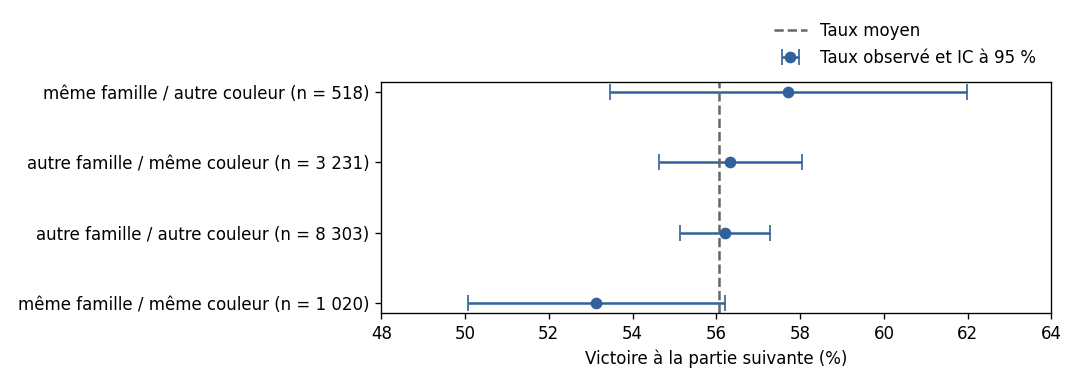

In [59]:
q = quatre.sort_values("taux")
taux_pct = 100 * q["taux"]
marges = [100 * (q["taux"] - q["ic_bas"]), 100 * (q["ic_haut"] - q["taux"])]
labels = [f"{nom} (n = {n:,})".replace(",", " ") for nom, n in q["parties"].items()]

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.errorbar(taux_pct, labels, xerr=marges, fmt="o", color="#30619b",
            capsize=5, label="Taux observé et IC à 95 %")
ax.axvline(100 * rep["win_suiv"].mean(), color="#666666",
           linestyle="--", label="Taux moyen")
ax.set(xlabel="Victoire à la partie suivante (%)", xlim=(48, 64))
ax.legend(loc="lower right", bbox_to_anchor=(1, 1), frameon=False)
fig.tight_layout()
plt.show()

Les quatre intervalles se chevauchent et couvrent le taux moyen. Le graphique montre l’incertitude de chaque taux. Le χ² de la section précédente porte sur la comparaison globale.

## 5.3 Analyses complémentaires

### 5.3.1 Répéter à couleur identique après ajustement

On compare les modèles avec et sans contrôles, puis on lit l’écart dans le modèle qui compare chaque joueur à lui-même. Le logit sert de vérification.

In [60]:
donnees = rep.dropna(subset=["elo_suiv_100", "format_partie_suiv"]).copy()
donnees["format_suiv"] = donnees["format_partie_suiv"].astype(str)
formules = {
    "M1 brut": "win_suiv ~ repete * meme_couleur",
    "M2 contrôles": "win_suiv ~ repete * meme_couleur + win + blancs_suiv + elo_suiv_100 + C(format_suiv)",
    "M3 effet fixe joueur": "win_suiv ~ repete * meme_couleur + win + blancs_suiv + elo_suiv_100 + C(format_suiv) + C(user_id)",
}
lignes, mod = [], {}
for nom, f in formules.items():
    m = smf.ols(f, data=donnees).fit(cov_type="cluster", cov_kwds={"groups": donnees["user_id"]})
    mod[nom] = m
    for v in ["repete", "meme_couleur", "repete:meme_couleur", "win", "blancs_suiv", "elo_suiv_100"]:
        if v in m.params:
            bas, haut = m.conf_int().loc[v]
            lignes.append({"modèle": nom, "variable": v, "effet (points)": 100 * m.params[v],
                           "IC bas": 100 * bas, "IC haut": 100 * haut, "p": m.pvalues[v]})
coef = pd.DataFrame(lignes)

In [62]:
print("R² :", {k: round(float(m.rsquared), 3) for k, m in mod.items()})
# Effet total de répéter quand on garde la couleur (β1 + β3) dans M3.
m3 = mod["M3 effet fixe joueur"]
total_m3 = m3.t_test("repete + repete:meme_couleur = 0")
print(f"Répéter à couleur gardée (β1 + β3) : {100 * total_m3.effect.item():+.1f} points, p = {total_m3.pvalue.item():.3f}")

R² : {'M1 brut': 0.0, 'M2 contrôles': 0.123, 'M3 effet fixe joueur': 0.131}
Répéter à couleur gardée (β1 + β3) : -3.7 points, p = 0.034


À couleur gardée, le modèle ajusté estime un écart de −3,7 points (p = 0,034, avant correction). Les modèles montrent une association plus nette avec l’Elo et la couleur. Ce résultat isolé sur la répétition reste à confirmer.

In [63]:
logit = smf.logit(formules["M2 contrôles"], data=donnees).fit(disp=False, cov_type="cluster",
                                                                cov_kwds={"groups": donnees["user_id"]})
effets_logit = logit.get_margeff(at="overall").summary_frame()
effets_logit = (100 * effets_logit[["dy/dx", "Conf. Int. Low", "Cont. Int. Hi."]]).join(effets_logit[["Pr(>|z|)"]])
effets_logit.columns = ["effet (points)", "IC bas", "IC haut", "p"]

### 5.3.2 Enchaîner les victoires au fil d’une session

Une nouvelle session commence après plus de 30 minutes entre deux parties. On teste si le rang dans la session est lié au résultat et si l’écart après une victoire subsiste une fois l’Elo pris en compte.

In [64]:
ecart = parties.groupby("user_id")["date"].diff().dt.total_seconds().div(60)
parties["nouvelle_session"] = ecart.isna() | (ecart > 30)
parties["session"] = parties.groupby("user_id")["nouvelle_session"].cumsum()
parties["rang"] = parties.groupby(["user_id", "session"]).cumcount() + 1
parties["rang_session"] = pd.cut(parties["rang"], [0, 1, 2, 3, 5, 10, 1000],
                                 labels=["1re", "2e", "3e", "4e-5e", "6e-10e", "11e et +"])
tailles = parties.groupby(["user_id", "session"]).size()

In [65]:
t = chi2(parties, "rang_session", y="win"); tests.append({**t, "test": "rang dans la session"})

In [66]:
t = chi2(trans, "win"); tests.append({**t, "test": "victoire précédente (brut)"})

In [67]:
fe = trans.dropna(subset=["elo_suiv_100"])
for nom, f in [("brut", "win_suiv ~ win"),
               ("écart Elo", "win_suiv ~ win + elo_suiv_100"),
               ("écart Elo + effet fixe joueur", "win_suiv ~ win + elo_suiv_100 + C(user_id)")]:
    m = smf.ols(f, data=fe).fit(cov_type="cluster", cov_kwds={"groups": fe["user_id"]})
    bas, haut = 100 * m.conf_int().loc["win"]
    print(f"{nom:32s} effet d’une victoire précédente : {100 * m.params['win']:+.1f} points "
          f"[{bas:+.1f} ; {haut:+.1f}], p = {m.pvalues['win']:.3f}")

brut                             effet d’une victoire précédente : +10.5 points [+6.0 ; +15.0], p = 0.000
écart Elo                        effet d’une victoire précédente : +3.1 points [+1.1 ; +5.0], p = 0.002


écart Elo + effet fixe joueur    effet d’une victoire précédente : +1.9 points [+0.1 ; +3.7], p = 0.042


Le rang dans la session n’est pas nettement associé au résultat (χ² p = 0,28). Après une victoire, l’écart brut de +10,5 points tombe à +1,9 point quand on tient compte de l’Elo et qu’on compare chaque joueur à lui-même.

### 5.3.3 Rejouer contre le même adversaire

On décrit les revanches en comparant les taux selon l’ouverture et l’issue de la première partie.

In [68]:
rev = trans[trans["meme_adversaire"] == 1].copy()

In [69]:
rev_conn = rev.dropna(subset=["repete"]).assign(choix=lambda d: d["repete"].map({1.0: "garde la famille", 0.0: "change de famille"}))
display(taux(rev_conn, "choix").round(3))

,parties,victoires,taux,ic_bas,ic_haut
choix,,,,,
change de famille,959,646,0.674,0.644,0.703
garde la famille,92,74,0.804,0.723,0.885


In [70]:
display(taux(rev.assign(premiere=rev["win"].map({1: "première partie gagnée", 0: "première partie non gagnée"})), "premiere").round(3))

,parties,victoires,taux,ic_bas,ic_haut
premiere,,,,,
première partie gagnée,752,569,0.757,0.726,0.787
première partie non gagnée,310,161,0.519,0.464,0.575


In [71]:
bilan_tests = pd.DataFrame(tests)
bilan_tests["p_Holm"] = multipletests(bilan_tests["p"], method="holm")[1]
bilan_tests["significatif (5 %, Holm)"] = bilan_tests["p_Holm"] < 0.05

# Conclusion

Après une victoire, les joueurs répètent leur famille d’ouverture dans 11,7 % des cas, contre 11,9 % après une nulle ou une défaite (χ² p = 0,65). Lorsqu’ils répètent après une victoire, le taux de victoire suivante est de 60,8 %, contre 60,6 % lorsqu’ils changent. L’écart ajusté est de −0,5 point. Ces résultats ne suffisent pas à établir une association entre la répétition après victoire et l’issue suivante.

Après la correction de Holm des tests du χ², deux associations brutes restent sous 5 %. Elles concernent la couleur et le résultat de la partie précédente. Le lien entre deux victoires successives diminue fortement quand on tient compte de l’Elo et des différences entre joueurs.

Sur les 1 062 revanches observées, le joueur gagne la suivante dans 75,7 % des cas après un premier succès, contre 51,9 % après une première partie non gagnée. La répétition de la famille correspond à un taux de 80,4 %, contre 67,4 % en changeant, mais seulement 92 enchaînements répètent la famille. Ces écarts restent descriptifs.

Les résultats portent sur les 30 comptes suivis. Le plafond par cadence et les choix des joueurs limitent leur généralisation.

## Sauvegarder les résultats

On enregistre dans `Collectes/<identifiant>/Resultats/` les tableaux des exercices, des tests et des régressions, la base nettoyée et une fiche de reproductibilité (versions des bibliothèques, fenêtre, empreinte SHA-256 des données).

N’importe qui peut relancer le notebook sur le même fichier et vérifier qu’il obtient les mêmes chiffres.

In [72]:
intervalle, mensuel = statistiques_temporelles(parties, DEBUT, FIN)
_, maxima_intervalle = series_resultats(intervalle)  # Séries de la fenêtre, pour l’export.
exporter_tableaux(cfg.RESULTS_DIR, parties, bilan, ouvertures, intervalle, mensuel, series, maxima, maxima_intervalle)
modeles.to_csv(cfg.RESULTS_DIR / "regressions_diagnostics.csv", index=False)
coefficients.to_csv(cfg.RESULTS_DIR / "regressions_coefficients.csv", index=False)
bilan_tests.to_csv(cfg.RESULTS_DIR / "gambit_tests.csv", index=False)
coef.to_csv(cfg.RESULTS_DIR / "gambit_regressions.csv", index=False)
ecrire_manifeste(identifiees, cfg.RESULTS_DIR, DEBUT, FIN)
print("Collecte conservée :", cfg.RUN_DIR.name)
print("Fichiers écrits :", len(list(cfg.RESULTS_DIR.iterdir())))

Collecte conservée : 20261125T121540_466859Z_84921e60
Fichiers écrits : 28
